In [ ]:
import importlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import nn
import plotting
from plotting import plot_heatmap

# Last inn lagrede endringer på nytt
importlib.reload(nn)
importlib.reload(plotting)

from nn import NeuralNetwork, train, mse
from data import make_runge_data
from optimizers import Adam

project_root = Path.cwd().parent if Path.cwd().name == "Code" else Path.cwd()
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
epochs = 1000
#create Runge data and standardize it
X_train, X_test, y_train, y_test = make_runge_data(100, 0.1, 0.2, 2026)
X_train, X_val,y_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = 2026)

x_mean = X_train.mean(axis=0)
x_std = X_train.std(axis = 0)

X_train = (X_train - x_mean)/x_std
X_val = (X_val - x_mean)/x_std
X_test = (X_test - x_mean)/x_std

mean = y_train.mean()
y_train -= mean
y_val -= mean
y_test -= mean


In [10]:
scores = {}
histories = {}
act_func = ["sigmoid", "relu", "leaky_relu"]
hidden_layers = [1, 2, 5]
nodes = [15, 50, 100]

for act in act_func:
    for layer in hidden_layers:
        for node in nodes:
            model = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [node]*layer + [y_train.shape[1]] , 
                                  activations=[act]*layer + ["identity"], cost = "mse",seed=2026 )
            optimizer = Adam(learning_rate=0.001)
            history = train(model, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=None, y_val=None)
            histories[(act, layer, node)] = history
            scores[(act, layer, node)] = mse(model.predict(X_val), y_val)

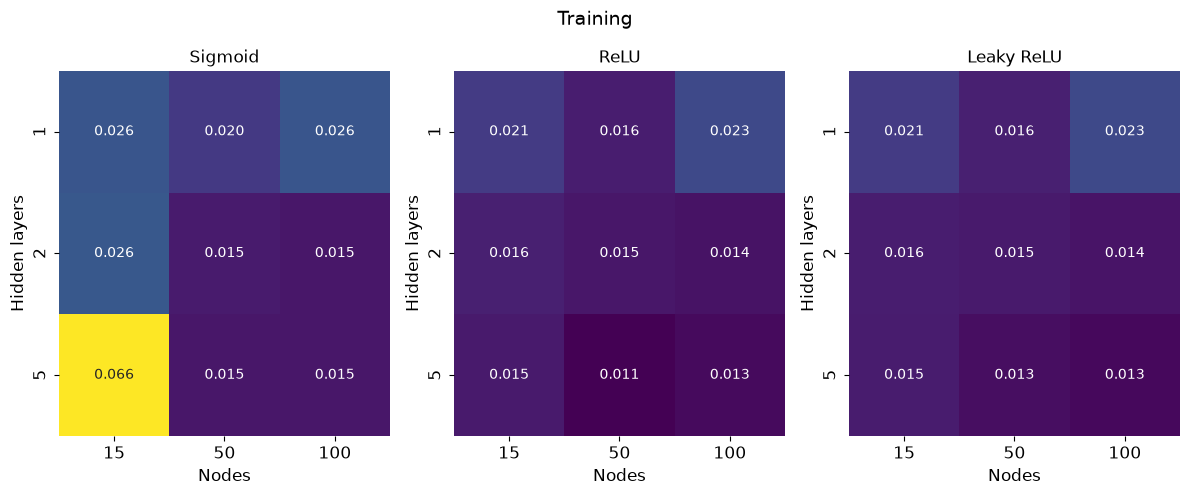

In [ ]:
train_scores = {key: history["train"][-1] for key, history in histories.items()}
matrices = [np.array([[train_scores[(act, layer, node)] for node in nodes] for layer in hidden_layers]) for act in act_func]
vmin = min(matrix.min() for matrix in matrices)
vmax = max(matrix.max() for matrix in matrices)
titles = ["Sigmoid", "ReLU", "Leaky ReLU"]
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, act, matrix, title in zip(axes, act_func, matrices, titles):
    plot_heatmap(
        values=matrix,
        x_labels=nodes,
        y_labels=hidden_layers,
        x_name="Nodes",
        y_name="Hidden layers",
        title=title,
        fmt=".3f",
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        cbar=False,
    )
    ax.set_xlabel("Nodes", fontsize=12)
    ax.set_ylabel("Hidden layers", fontsize=12)
    ax.tick_params(axis="both", labelsize=12)

fig.suptitle("Training", fontsize=14)
plt.tight_layout()
fig.savefig(figures_dir / "part_cd_activation_train_mse.pdf", bbox_inches="tight")
plt.show()

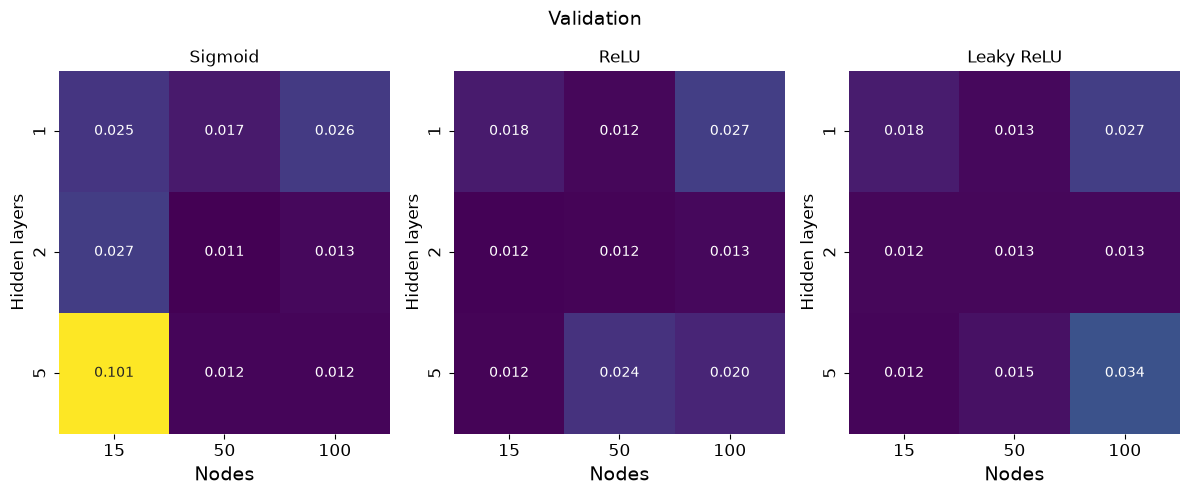

In [ ]:
matrices = [np.array([[scores[(act, layer, node)] for node in nodes] for layer in hidden_layers]) for act in act_func]
vmin = min(matrix.min() for matrix in matrices)
vmax = max(matrix.max() for matrix in matrices)
titles = ["Sigmoid", "ReLU", "Leaky ReLU"]
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, act, matrix, title in zip(axes, act_func, matrices, titles):
    plot_heatmap(
        values=matrix,
        x_labels=nodes,
        y_labels=hidden_layers,
        x_name="Nodes",
        y_name="Hidden layers",
        title=title,
        fmt=".3f",
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        cbar=False,
    )
    ax.set_xlabel("Nodes", fontsize=14)
    ax.set_ylabel("Hidden layers", fontsize=12)
    ax.tick_params(axis="both", labelsize=12)
fig.suptitle("Validation", fontsize=14)
plt.tight_layout()
fig.savefig(figures_dir / "part_cd_activation_validation_mse.pdf", bbox_inches="tight")
plt.show()

In [24]:
best_key = min(scores, key=scores.get)
print("Best(activation function, nuber of nodes, Hidden layers):", best_key)
print("Validation MSE:", scores[best_key])

Best(activation function, nuber of nodes, Hidden layers): ('sigmoid', 2, 50)
Validation MSE: 0.011009484740489756


In [25]:
best_model = NeuralNetwork(layer_sizes=[X_train.shape[1], 50, 50, y_train.shape[1]],
                           activations=["sigmoid", "sigmoid", "identity"], cost = "mse", seed = 2026)
optimizer= Adam(learning_rate=0.001)
history = train(best_model, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=None, y_val=None)
test_mse = best_model.cost(X_test, y_test)
print(f"Test-MSE:{test_mse:.6f}")

Test-MSE:0.014063


Part D Regularization
-

In [26]:
#L2 Regularization, for the other arcitectures # hidden layers and nodes 
act_func = ['sigmoid','relu', 'leaky_relu']
lambdas = [0.0, 1e-4, 1e-3, 1e-2]
gammas = [1e-4, 1e-3, 1e-2]
scoresl2 = {}

for act in act_func:
    for layer in [1, 2, 5]:
        for node in [15, 50, 100]:

            for lam in lambdas:
                for gamma in gammas:
                    modelL2 = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [node]*layer + [y_train.shape[1]],
                                            activations=[act]*layer + ["identity"], cost="mse", l1=0.0, l2=lam, seed=2026)
                    optimizer = Adam(learning_rate=gamma)
                    historyL2 = train(modelL2, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=X_val, y_val=y_val)
                    scoresl2[(act, layer, node, lam, gamma)] = mse(modelL2.predict(X_val), y_val)


In [29]:
valid_scores_l2 = {key: value for key, value in scoresl2.items() if np.isfinite(value)}
best_act_l2, best_layer_l2, best_node_l2, best_lambda_l2, best_gamma_l2 = min(valid_scores_l2, key=valid_scores_l2.get)
print((best_act_l2, best_layer_l2, best_node_l2, best_lambda_l2, best_gamma_l2))
print(f"Best validation MSE:", valid_scores_l2[(best_act_l2, best_layer_l2, best_node_l2, best_lambda_l2, best_gamma_l2)])

('sigmoid', 2, 50, 0.0, 0.001)
Best validation MSE: 0.011009484740489756


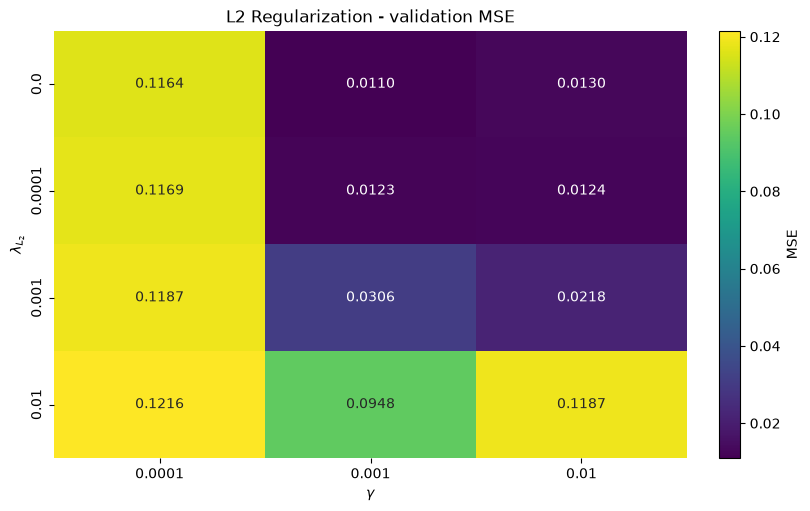

In [ ]:
mse_grid = np.array([
    [scoresl2[(best_act_l2, best_layer_l2, best_node_l2, lam, gamma)] for gamma in gammas]
    for lam in lambdas
])
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
plot_heatmap(
    values=mse_grid,
    x_labels=gammas,
    y_labels=lambdas,
    x_name=r"$\gamma$",
    y_name=r"$\lambda_{L_2}$",
    title="L2 Regularization - validation MSE",
    fmt=".4f",
    ax=ax,
    cbar=False,
)
fig.colorbar(ax.collections[0], ax=ax, label="MSE")
fig.savefig(figures_dir / "part_cd_l2_validation_mse.pdf", bbox_inches="tight")
plt.show()

In [30]:
#L1 Regularization, for the other arcitectures # hidden layers and nodes 
lambdas = [0.0, 1e-4, 1e-3, 1e-2]
gammas = [1e-4, 1e-3, 1e-2]
scoresl1 = {}

for act in act_func:
    for layer in [1, 2, 5]:
            for node in [15, 50, 100]:

                for lam in lambdas:
                    for gamma in gammas:
                        modelL1 = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [node]*layer + [y_train.shape[1]], activations=[act]*layer + ["identity"], cost="mse", l1=lam, l2=0.0, seed=2026)
                        optimizer = Adam(learning_rate=gamma)
                        historyL1 = train(modelL1, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026, X_val=X_val, y_val=y_val)
                        scoresl1[(act, layer, node, lam, gamma)] = mse(modelL1.predict(X_val), y_val)


valid_scores_l1 = {key: value for key, value in scoresl1.items() if np.isfinite(value)}
best_act_l1, best_layer_l1, best_node_l1, best_lambda_l1, best_gamma_l1 = min(valid_scores_l1, key=valid_scores_l1.get)
print((best_act_l1, best_layer_l1, best_node_l1, best_lambda_l1, best_gamma_l1))
print(f"Best validation MSE:", valid_scores_l1[(best_act_l1, best_layer_l1, best_node_l1, best_lambda_l1, best_gamma_l1)])

('sigmoid', 2, 50, 0.0, 0.001)
Best validation MSE: 0.011009484740489756


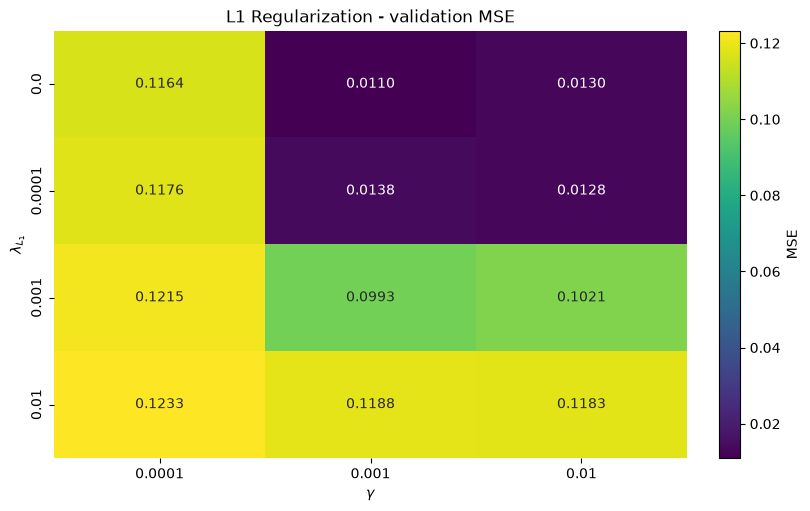

In [ ]:
mse_grid1 = np.array([
    [scoresl1[(best_act_l1, best_layer_l1, best_node_l1, lam, gamma)] for gamma in gammas]
    for lam in lambdas
])
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
plot_heatmap(
    values=mse_grid1,
    x_labels=gammas,
    y_labels=lambdas,
    x_name=r"$\gamma$",
    y_name=r"$\lambda_{L_1}$",
    title="L1 Regularization - validation MSE",
    fmt=".4f",
    ax=ax,
    cbar=False,
)
fig.colorbar(ax.collections[0], ax=ax, label="MSE")
fig.savefig(figures_dir / "part_cd_l1_validation_mse.pdf", bbox_inches="tight")
plt.show()

In [ ]:
#Training the L2 model again
best_modelL2 = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [best_node_l2]*best_layer_l2 + [y_train.shape[1]],
                                        activations=[best_act_l2]*best_layer_l2 + ["identity"], cost="mse", l1=0.0, l2=best_lambda_l2, seed=2026)
optimizer = Adam(learning_rate=best_gamma_l2)
historyL2 = train(best_modelL2, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026)
print(f"Best test MSE L2:", best_modelL2.cost(X_test, y_test))

Best test MSE L2: 0.0140628602127472


In [ ]:
#Training the L1 model again
best_modelL1 = NeuralNetwork(layer_sizes = [X_train.shape[1]] + [best_node_l1]*best_layer_l1 + [y_train.shape[1]],
                                        activations=[best_act_l1]*best_layer_l1 + ["identity"], cost="mse", l1=best_lambda_l1, l2=0.0, seed=2026)
optimizer = Adam(learning_rate=best_gamma_l1)
historyL1 = train(best_modelL1, optimizer, X=X_train, y=y_train, epochs=epochs, batch_size=None, seed=2026)
print(f"Best test MSE L1:", best_modelL1.cost(X_test, y_test))

Best test MSE L1: 0.0140628602127472


In [ ]:
key = ("sigmoid", 2, 50, 1e-2, 1e-3)

print(f"L1: {scoresl1[key]:.12f}")
print(f"L2: {scoresl2[key]:.12f}")
print(f"Forskjell: {scoresl1[key] - scoresl2[key]:.3e}")

L1: 0.118754016434
L2: 0.094792318733
Forskjell: 2.396e-02


In [31]:
# Sammenlign beste L1-konfigurasjon mot lambda=0 for samme arkitektur og gamma
act, layer, node, lam, gamma = (
    best_act_l1, best_layer_l1, best_node_l1, best_lambda_l1, best_gamma_l1
)
baseline = scoresl1[(act, layer, node, 0.0, gamma)]
regularized = scoresl1[(act, layer, node, lam, gamma)]

print(f"Lambda=0: {baseline:.6f}")
print(f"Lambda={lam}: {regularized:.6f}")

Lambda=0: 0.011009
Lambda=0.0: 0.011009


In [32]:
# Sammenlign beste L1-konfigurasjon mot lambda=0 for samme arkitektur og gamma
act, layer, node, lam, gamma = (
    best_act_l2, best_layer_l2, best_node_l2, best_lambda_l2, best_gamma_l2
)
baseline = scoresl2[(act, layer, node, 0.0, gamma)]
regularized = scoresl2[(act, layer, node, lam, gamma)]

print(f"Lambda=0: {baseline:.6f}")
print(f"Lambda={lam}: {regularized:.6f}")

Lambda=0: 0.011009
Lambda=0.0: 0.011009
